In [3]:
! pip install statsmodels


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

import warnings; warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
%matplotlib inline

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.model_selection import TimeSeriesSplit

In [2]:
df = pd.read_csv("../data/us_monthly_retail_sales_wrangled.csv")
df.head()

,Unnamed: 0,month,year,naics_Code,kind_of_business,industry,sales
0,0,1,2022,441,Motor vehicle and parts dealers,Automotive,113548.0
1,1,1,2022,"44,114,412",Automobile and other motor vehicle dealers,Automotive,104500.0
2,2,1,2022,4411,Automobile dealers,Automotive,96689.0
3,3,1,2022,44111,New car dealers,Automotive,84442.0
4,4,1,2022,44112,Used car dealers,Automotive,12247.0


### **Creating an Object Oriented Sarima-Forecasting Production Pipeline Class**

In [3]:
# Here we created the Object-Oriented SARIMA-Forecasting Pipeline
# Step 1;Initialize the Class
class SARIMAForecastingPipeline:
    def __init__(self, order = (1, 1, 1), seasonal_order = (1, 1, 1, 12)):
        self.order = order
        self.seasonal_order = seasonal_order
        self.fitted_model = None

# step 2; Data Ingestion and Preprocessing
    def prepare_data(self, df_path, industry_name = 'Automotive'):
        df = pd.read_csv(df_path)
        df['date'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str) + '-01')
        time_series_data = df[df['industry'] == 'Automotive'].groupby('date')['sales'].sum().to_frame(name = 'sales').asfreq('MS')
        return time_series_data['sales']

    def train_and_validate(self, series, train_ratio = 0.8):
        split_idx = int(len(series) * train_ratio)
        train_series = series.iloc[:split_idx]
        test_series = series.iloc[split_idx:]

        # Fit the model pn training partition
        sales_model = SARIMAX(train_series, order = self.order, seasonal_order = self.seasonal_order).fit(disp = False)
        predictions = sales_model.forecast(steps=len(test_series))

        # Metric evaluations
        mape = np.mean(np.abs((test_series - predictions) / test_series)) * 100
        rmse = np.sqrt(np.mean((test_series - predictions) ** 2))

        print("--- SARIMA Validation Metrics ---")
        print(f"Validation MAPE: {mape:.2f}%")
        print(f"Validation RMSE: ${rmse:,.2f}")
        return sales_model

        # Production refitting; refitting the complete dataset prior to producing future predictions
        # from 2010 through December 2022
    def fit_production(self, full_series):
        self.fitted_model = SARIMAX(full_series, order = self.order, seasonal_order = self.seasonal_order).fit(disp = False)
        print("Here's the Production SARIMA model fitted on 100% of the historical data.")

        # Here we generate out-of-sample forecasts with confidence intervals
    def predict_future(self, steps = 48):
        if self.fitted_model is None:
            raise ValueError('Fit the model on production data first using a .fit_production()')

        forecast_object = self.fitted_model.get_forecast(steps = steps)
        forecast_df = forecast_object.summary_frame()

        return forecast_df


# Here we create a pipeline Execution workflow
pipeline = SARIMAForecastingPipeline(order = (1, 1, 1), seasonal_order = (1, 1, 1, 12))

# Loading the dataset
sales_series = pipeline.prepare_data("../data/us_monthly_retail_sales_wrangled.csv")

# Validate the model's accuracy
pipeline.train_and_validate(sales_series)

# Refitting a complete dataset from(2010 - 2022) and Forecast 2026 sales
pipeline.fit_production(sales_series)
forecast_sales_2026 = pipeline.predict_future(steps = 48).loc['2026-01-01':'2026-12-01', ['mean', 'mean_ci_lower', 'mean_ci_upper']]
print("\n--- 2026 Production Forecast Sample ---")
print(forecast_sales_2026.head(3))


--- SARIMA Validation Metrics ---
Validation MAPE: 64.16%
Validation RMSE: $313,251.93
Here's the Production SARIMA model fitted on 100% of the historical data.

--- 2026 Production Forecast Sample ---
sales                mean  mean_ci_lower  mean_ci_upper
2026-01-01  481704.296735  172143.406861  791265.186608
2026-02-01  490531.307689  172278.744317  808783.871061
2026-03-01  561976.584808  235746.889540  888206.280076


In [4]:
df['sales'].mean()

np.float64(21850.771139182885)

In [5]:
"""
Validation MAPE: 64.16%
Validation RMSE: $313,251.93

These metrics which are relative to monthly sales around USD 511 K indicates the SARIMA model is struggling with significant forecast error and high variance
Here's the main cause of the high MAPE;
the standard SARIMA assumes linear stationary pattern in sales and with the extreme structural shock caused by the COVID pandemic that lead to surge in sales, it heavily distorts ARIMA parameters and the standard error estimate.

The Log / Variance stabilization strategy; if the sales magnitude grows over time, the variance of the errors increases proportionally.
By applying logarithm transformation which stabilizes the variance and converts multiplicative seasonality into an additive structure before fitting the model.

"""

"\nValidation MAPE: 64.16%\nValidation RMSE: $313,251.93\n\nThese metrics which are relative to monthly sales around USD 511 K indicates the SARIMA model is struggling with significant forecast error and high variance\nHere's the main cause of the high MAPE;\nthe standard SARIMA assumes linear stationary pattern in sales and with the extreme structural shock caused by the COVID pandemic that lead to surge in sales, it heavily distorts ARIMA parameters and the standard error estimate.\n\nThe Log / Variance stabilization strategy; if the sales magnitude grows over time, the variance of the errors increases proportionally.\nBy applying logarithm transformation which stabilizes the variance and converts multiplicative seasonality into an additive structure before fitting the model.\n\n"

In [6]:
# Here we create variance stabilization strategy pipeline
# Step 1;Initialize the Class
class SARIMAForecastingPipelineStabilized:
    def __init__(self, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)):
        self.order = order
        self.seasonal_order = seasonal_order
        self.fitted_model = None

    # step 2; Data Ingestion and Preprocessing
    def prepare_data(self, df_path, industry_name='Automotive'):
        df = pd.read_csv(df_path)
        df['date'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str) + '-01')
        time_series_data = df[df['industry'] == 'Automotive'].groupby('date')['sales'].sum().to_frame(
            name='sales').asfreq('MS')
        return time_series_data['sales']

    def train_and_validate(self, series, train_ratio=0.8):
        split_idx = int(len(series) * train_ratio)
        train_series = series.iloc[:split_idx]
        test_series = series.iloc[split_idx:]

        # Fit the model pn training partition
        sales_model = SARIMAX(train_series, order=self.order, seasonal_order=self.seasonal_order).fit(disp=False)
        predictions = sales_model.forecast(steps=len(test_series))

        # Metric evaluations
        mape = np.mean(np.abs((test_series - predictions) / test_series)) * 100
        rmse = np.sqrt(np.mean((test_series - predictions) ** 2))

        print("--- SARIMA Validation Metrics ---")
        print(f"Validation MAPE: {mape:.2f}%")
        print(f"Validation RMSE: ${rmse:,.2f}")
        return sales_model

        # Production refitting; refitting the complete dataset prior to producing future predictions
        # from 2010 through December 2022

    def fit_production(self, full_series):
        full_series_log = np.log(full_series)
        self.fitted_model = SARIMAX(full_series, order=self.order, seasonal_order=self.seasonal_order).fit(disp=False)
        print("Here's the Production SARIMA model fitted on 100% of the historical data.")

        # Here we generate out-of-sample forecasts with confidence intervals

    def predict_future(self, steps=48):
        if self.fitted_model is None:
            raise ValueError('Fit the model on production data first using a .fit_production()')

        forecast_object = self.fitted_model.get_forecast(steps=steps)
        forecast_log_df = forecast_object.summary_frame()

        # Exponentiate forecast values & confidence intervals back to standard sales scale
        forecast_df = pd.DataFrame(index = forecast_log_df)
        forecast_df['mean'] = np.exp(forecast_log_df['mean'])
        forecast_df['mean_ci_lower'] = np.exp(forecast_log_df['mean_ci_lower'])
        forecast_df['mean_ci_upper'] = np.exp(forecast_log_df['mean_ci_upper'])


        return forecast_df

# Here we create a pipeline Execution workflow
pipeline = SARIMAForecastingPipeline(order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))

# Loading the dataset
sales_series = pipeline.prepare_data("../data/us_monthly_retail_sales_wrangled.csv")

# Validate the model's accuracy
pipeline.train_and_validate(sales_series)

# Refitting a complete dataset from(2010 - 2022) and Forecast 2026 sales
pipeline.fit_production(sales_series)
forecast_sales_2026 = pipeline.predict_future(steps=48).loc[
    '2026-01-01':'2026-12-01', ['mean', 'mean_ci_lower', 'mean_ci_upper']]
print("\n--- 2026 Production Forecast Sample ---")
print(forecast_sales_2026.head(3))


--- SARIMA Validation Metrics ---
Validation MAPE: 64.16%
Validation RMSE: $313,251.93
Here's the Production SARIMA model fitted on 100% of the historical data.

--- 2026 Production Forecast Sample ---
sales                mean  mean_ci_lower  mean_ci_upper
2026-01-01  481704.296735  172143.406861  791265.186608
2026-02-01  490531.307689  172278.744317  808783.871061
2026-03-01  561976.584808  235746.889540  888206.280076


#### **Build an Objected-Oriented Gradient Boosting Forecasting Pipeline**

In [7]:
# Unlike the linear models like SARIMA, the tree based models such as (GradientBoostingRegressor) cannot inherently extrapolate linear trends or
# even understand the time sequence out of the woods.
# Here we're actually building class that transforms the problem into supervised learning task using stationarity transformations, recursive forecasting and residual sampling
"""
--------
    1. Variance stabilization: work on L = log(sales).
    2. Gradient boosting cannot extrapolate a trend, so the target is the
       year-over-year log growth  g_t = L_t - L_{t-12}  (this removes both trend
       and most of the seasonal level).
    3. Features come from the past only: lagged growth, month-over-month change,
       rolling mean growth and month-of-year (sin/cos).
    4. Forecast recursively: each predicted month feeds the next month's features.
    5. Intervals: out-of-fold residuals are resampled into simulated paths.

-------
"""

"\n--------\n    1. Variance stabilization: work on L = log(sales).\n    2. Gradient boosting cannot extrapolate a trend, so the target is the\n       year-over-year log growth  g_t = L_t - L_{t-12}  (this removes both trend\n       and most of the seasonal level).\n    3. Features come from the past only: lagged growth, month-over-month change,\n       rolling mean growth and month-of-year (sin/cos).\n    4. Forecast recursively: each predicted month feeds the next month's features.\n    5. Intervals: out-of-fold residuals are resampled into simulated paths.\n\n-------\n"

Data range: 2010-01 to 2022-12 (156 months)
--- Gradient Boosting Validation Metrics ---
Validation MAPE: 49.29%
Validation RMSE: $245,731.99
Production gradient boosting model fitted on 100% of the data (2010-01 to 2022-12).

--- 2026 Monthly Sales Forecast ---
           forecast   lower_95    upper_95
Jan 2026  532267.34  330200.78   937163.21
Feb 2026  536590.81  323018.86   975900.37
Mar 2026  615469.78  341427.25  1091021.63
Apr 2026  619170.67  390922.86  1190200.95
May 2026  618865.99  386270.77  1153576.77
Jun 2026  637979.45  377093.41  1197478.09
Jul 2026  577973.61  353239.60  1134165.41
Aug 2026  616347.26  389418.01  1284151.86
Sep 2026  565608.44  364267.34  1112532.79
Oct 2026  597620.92  349016.63  1124144.49
Nov 2026  525474.17  323912.43   993484.19
Dec 2026  579955.63  345293.28  1014915.20

Projected total 2026 sales: $7,023,324.06

--- Feature importance ---
g_lag12      0.563
mom_lag1     0.181
g_roll3      0.062
g_lag3       0.043
g_roll6      0.041
g_lag1      

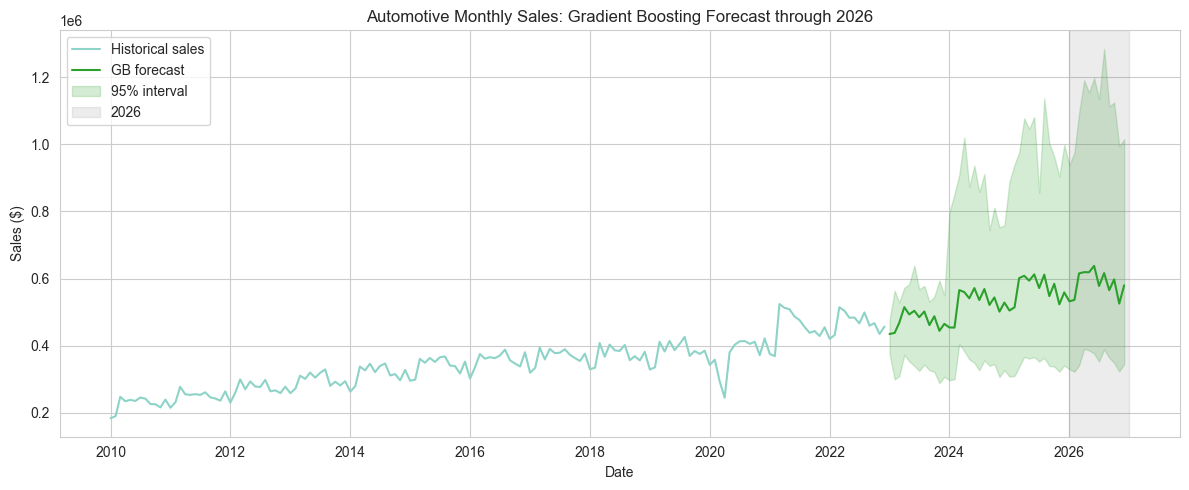

In [8]:
# Here we build an OOP GBoosting forecasting pipeline with log variance stabilization, recursive multistep forecasting and simulation based
# prediction intervals

# Step 1: Initialize the class
class GradientBoostingForecastingPipeline: #entire pipeline object including data prep, feature creation, model training and forecasting methods
# the months needed to build lag 12 growth features, since the model relies on year-over-year growth calculated over 12 month window in
# addition to another lagged features going back another 12 months, pipeline requires 24 miths of contunous historical data before it can build
# its very first training row

    MIN_HISTORY = 24  # months needed to build the lag-12 growth features

    def __init__(self, industry_name='Automotive', n_estimators=300,
                 learning_rate=0.03, max_depth=2, subsample=0.8, random_state=42):
        self.industry_name = industry_name
        self.params = dict(n_estimators=n_estimators, learning_rate=learning_rate,
                           max_depth=max_depth, subsample=subsample,
                           random_state=random_state)
        self.random_state = random_state
        self.model = None # instance for trained GBRegressor model object
        self.residuals_ = None  # stores out-of-fold prediction errors which are later resampled to calculate the empirical forecast confidence intervals
        self.log_history_ = None  # stores the log transformed sales ln(sales) required to recursively generate features for future dates
        self.last_date_ = None # keeps track of the final Timestamp in the training data such that out-of-sample forecast know exactly where to begin

        # defines explicit ordered list of the input feature names used by regressor
        self.feature_names_ = ['g_lag1', 'g_lag2', 'g_lag3', 'g_lag12', # YoY growth rate lag from 1,2,3, 12 months prior
                               'g_roll3', 'g_roll6', # 3 - 6 months rolling averages of YoY growth
                               'mom_lag1', # MoM growth rate (ln_sales - ln_sales_t)
                               'month_sin', 'month_cos'] # trigonometric sine and cosine encodings of calendar month (1 - 12)

        self.metrics = {}  # empty dictionary which stores evaluation performance output (MAPE and RMSE) after model validation

    # Step 2: Data ingestion and preprocessing
    def prepare_data(self, df_path):
        df = pd.read_csv(df_path)
        df['date'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str) + '-01')
        series = (df[df['industry'] == self.industry_name].groupby('date')['sales'].sum().asfreq('MS'))

        if series.empty:
            raise ValueError(f"No rows found for industry '{self.industry_name}'.")
        if series.isna().any():
            series = series.interpolate()
            print("Warning: missing months were linearly interpolated.")
        if (series <= 0).any():
            raise ValueError("Log transform needs strictly positive sales.")

        print(f"Data range: {series.index.min():%Y-%m} to {series.index.max():%Y-%m} "
              f"({len(series)} months)")
        return series

   # ---- Feature engineering (works on many paths at once) ----
    def _features(self, L, month):
        """L: array (n_paths, n_history) of log sales. month: calendar month (1-12) being predicted."""
        g = lambda k: L[:, -k] - L[:, -k - 12]  # growth k months ago
        g_lags = np.column_stack([g(k) for k in range(1, 7)])
        mom = L[:, -1] - L[:, -2]
        ang = 2 * np.pi * month / 12
        n = L.shape[0]
        return np.column_stack([
            g_lags[:, 0], g_lags[:, 1], g_lags[:, 2], g(12),
            g_lags[:, :3].mean(axis=1), g_lags.mean(axis=1), mom,
            np.full(n, np.sin(ang)), np.full(n, np.cos(ang))
        ])

    def _build_training_set(self, L, dates):
        X, y = [], []
        for t in range(self.MIN_HISTORY, len(L)):
            X.append(self._features(L[None, :t], dates[t].month)[0])
            y.append(L[t] - L[t - 12])
        return np.array(X), np.array(y)

    def _fit_core(self, series):
        L = np.log(series.values.astype(float))
        X, y = self._build_training_set(L, series.index)

        # Out-of-fold one-step residuals (used later for prediction intervals)
        oof = []
        for tr, te in TimeSeriesSplit(n_splits=5).split(X):
            m = GradientBoostingRegressor(**self.params).fit(X[tr], y[tr])
            oof.extend(y[te] - m.predict(X[te]))
        oof = np.array(oof)
        self.residuals_ = oof - oof.mean()  # centered so intervals surround the point forecast

        self.model = GradientBoostingRegressor(**self.params).fit(X, y)
        self.log_history_ = L
        self.last_date_ = series.index.max()

    # ---- Recursive multi-step forecast ----
    def _recursive(self, steps, n_sims=0):
        rng = np.random.default_rng(self.random_state)
        paths = max(n_sims, 1)
        L = np.tile(self.log_history_, (paths, 1))
        for h in range(1, steps + 1):
            month = (self.last_date_ + pd.DateOffset(months=h)).month
            g_hat = self.model.predict(self._features(L, month))
            if n_sims:
                g_hat = g_hat + rng.choice(self.residuals_, size=paths)
            L = np.column_stack([L, L[:, -12] + g_hat])
        return L[:, -steps:]  # log-scale forecasts, shape (paths, steps)

    # Step 3: Train/test validation (true multi-step, no peeking)
    def train_and_validate(self, series, train_ratio=0.8):
        split_idx = int(len(series) * train_ratio)
        train_series, test_series = series.iloc[:split_idx], series.iloc[split_idx:]

        self._fit_core(train_series)
        preds = np.exp(self._recursive(len(test_series))[0])
        preds = pd.Series(preds, index=test_series.index)

        mape = np.mean(np.abs((test_series - preds) / test_series)) * 100
        rmse = np.sqrt(np.mean((test_series - preds) ** 2))
        self.metrics = {'MAPE': mape, 'RMSE': rmse}

        print("--- Gradient Boosting Validation Metrics ---")
        print(f"Validation MAPE: {mape:.2f}%")
        print(f"Validation RMSE: ${rmse:,.2f}")
        return preds

    # Step 4: Production refit on 100% of the historical data
    def fit_production(self, full_series):
        self._fit_core(full_series)
        print(f"Production gradient boosting model fitted on 100% of the data "
              f"({full_series.index.min():%Y-%m} to {self.last_date_:%Y-%m}).")

    # Step 5: Out-of-sample forecasts with intervals, back on the sales scale
    def predict_future(self, steps=None, target_year=None, n_sims=500, alpha=0.05):
        if self.model is None:
            raise ValueError('Fit the model first using .fit_production()')
        if steps is None:
            if target_year is None:
                raise ValueError('Provide steps or target_year.')
            steps = ((target_year - self.last_date_.year) * 12 + (12 - self.last_date_.month))
            if steps <= 0:
                raise ValueError('target_year is not after the end of the data.')

        idx = pd.date_range(self.last_date_ + pd.DateOffset(months=1), periods=steps, freq='MS')
        point = np.exp(self._recursive(steps)[0])  # exp() back-transform
        sims = np.exp(self._recursive(steps, n_sims = n_sims))
        lo, hi = np.percentile(sims, [alpha / 2 * 100, (1 - alpha / 2) * 100], axis = 0)

        return pd.DataFrame({'mean': point, 'mean_ci_lower': lo, 'mean_ci_upper': hi}, index=idx)

    # Step 6: 2026-specific table and annual total
    def forecast_year(self, year=2026, alpha=0.05):
        full = self.predict_future(target_year=year, alpha=alpha)
        year_df = full.loc[f'{year}-01-01':f'{year}-12-01'].copy()
        year_df.columns = ['forecast', 'lower_95', 'upper_95']
        year_df.index = year_df.index.strftime('%b %Y')
        total = year_df['forecast'].sum()

        print(f"\n--- {year} Monthly Sales Forecast ---")
        print(year_df.round(2).to_string())
        print(f"\nProjected total {year} sales: ${total:,.2f}")
        return year_df, total

    # Step 7: Interpretation and visualization
    def feature_importance(self):
        imp = pd.Series(self.model.feature_importances_, index=self.feature_names_)
        return imp.sort_values(ascending=False)

    def plot_forecast(self, series, year=2026, alpha=0.05, save_path=None):
        full = self.predict_future(target_year=year, alpha=alpha)
        fig, ax = plt.subplots(figsize=(12, 5))
        ax.plot(series.index, series.values, label='Historical sales')
        ax.plot(full.index, full['mean'], color='tab:green', label='GB forecast')
        ax.fill_between(full.index, full['mean_ci_lower'], full['mean_ci_upper'],
                        color='tab:green', alpha=0.2,
                        label=f'{int((1 - alpha) * 100)}% interval')
        ax.axvspan(pd.Timestamp(f'{year}-01-01'), pd.Timestamp(f'{year}-12-31'),
                   color='grey', alpha=0.15, label=str(year))
        ax.set_title(f'{self.industry_name} Monthly Sales: Gradient Boosting Forecast through {year}')
        ax.set_xlabel('Date')
        ax.set_ylabel('Sales ($)')
        ax.legend()
        plt.tight_layout()
        if save_path:
            fig.savefig(save_path, dpi=150)
        plt.show()


# Pipeline execution workflow
pipeline = GradientBoostingForecastingPipeline(industry_name='Automotive')

# Load the dataset
sales_series = pipeline.prepare_data("../data/us_monthly_retail_sales_wrangled.csv")

# Validate the model's accuracy (compare this MAPE/RMSE with SARIMA's)
pipeline.train_and_validate(sales_series)

# Refit on the complete dataset and forecast 2026
pipeline.fit_production(sales_series)
forecast_2026, total_2026 = pipeline.forecast_year(2026)

print("\n--- Feature importance ---")
print(pipeline.feature_importance().round(3))

pipeline.plot_forecast(sales_series, year=2026)
forecast_2026.to_csv("gb_sales_forecast_2026.csv")